# Lab 2 — What Did the Campaign Deliver?
# Name: Yeromenko Marharyta | Group: KM-42


## Setup


In [9]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/3")

programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
commercials = pd.read_parquet(f"{DATA}/commercials.parquet")
rate_card = pd.read_parquet(f"{DATA}/rate_card.parquet")

## Task 1.1 — Size

In [10]:
print("Spots:", len(commercials))
print("Pods:", commercials['pod_id'].nunique())
print("Brands:", commercials['brand'].nunique())
print("Categories:", commercials['category'].nunique())

brand_a_spots = commercials[commercials['brand'] == 'BRAND_A'].copy()
print("BRAND_A spots:", len(brand_a_spots))

# table: BRAND_A spots by network
brand_a_by_net = brand_a_spots.groupby('network_code').size().reset_index(name='spots')
brand_a_by_net = brand_a_by_net.sort_values('spots', ascending=False).reset_index(drop=True)
display(brand_a_by_net)

Spots: 167720
Pods: 22359
Brands: 95
Categories: 14
BRAND_A spots: 300


,network_code,spots
0,FNC,40
1,HGTV,39
2,FX,38
3,HIST,37
4,FOOD,33
5,BRAVO,33
6,ABC,29
7,CBS,22
8,NBC,16
9,FOX,13


## Task 1.2 — Ad load


In [11]:
commercials['clock_hour'] = commercials['start_ts'].dt.floor('h')
hourly_ad_sec = commercials.groupby(['network_code', 'clock_hour'])['length_sec'].sum().reset_index()
hourly_ad_sec['ad_minutes'] = hourly_ad_sec['length_sec'] / 60.0

ad_load_table = hourly_ad_sec.groupby('network_code')['ad_minutes'].mean().reset_index()
ad_load_table['ad_minutes'] = ad_load_table['ad_minutes'].round(1)
ad_load_table = ad_load_table.sort_values('ad_minutes', ascending=False).reset_index(drop=True)

# table: ad minutes per hour by network
display(ad_load_table)

heaviest_net = ad_load_table.loc[0, 'network_code']
print("Heaviest ad load:", heaviest_net)

,network_code,ad_minutes
0,FNC,15.6
1,BRAVO,13.4
2,HGTV,13.3
3,HIST,13.2
4,FOOD,13.1
5,FX,12.9
6,CBS,12.1
7,ABC,11.8
8,FOX,11.8
9,NBC,11.8


Heaviest ad load: FNC


**Answer:** The broadcast networks (ABC, CBS, NBC, FOX) have whole hours without any national commercials because parts of their daily schedule are handed over to local affiliate stations (for example, local morning and evening news), and those ad breaks are sold locally rather than nationally. In addition, hours with paid programming or special events like the vice-presidential debate do not carry national commercial breaks.

## Task 1.3 — Price everything

In [12]:
# Join each spot to programs for its program_name
spots = commercials.merge(programs[['telecast_id', 'program_name']], on='telecast_id', how='left')

# Split rate_card into program rows and time rows
rc_prog = rate_card[rate_card['program_name'].notna() & (rate_card['program_name'] != '')].copy()
rc_time = rate_card[rate_card['program_name'].isna() | (rate_card['program_name'] == '')].copy()

# 1. Match program rows first on network and program_name
matched_prog = spots.merge(
    rc_prog[['network_code', 'program_name', 'daypart', 'cost_30s_usd']],
    on=['network_code', 'program_name'],
    how='inner'
)
matched_prog['is_prog_row'] = True

# 2. Match remaining spots using broadcast weekday and minutes since 06:00
unmatched_spots = spots[~spots['ad_airing_id'].isin(matched_prog['ad_airing_id'])].copy()

bc_ts = unmatched_spots['start_ts'] - pd.Timedelta(hours=6)
unmatched_spots['bc_weekday'] = bc_ts.dt.dayofweek
unmatched_spots['bc_minute'] = bc_ts.dt.hour * 60 + bc_ts.dt.minute + bc_ts.dt.second / 60.0

def to_bc_minutes(time_str):
    h, m = map(int, str(time_str).split(':'))
    return h * 60 + m - 360

rc_time['start_min'] = rc_time['start_time'].apply(to_bc_minutes)
rc_time['end_min'] = rc_time['end_time'].apply(to_bc_minutes)
rc_time_exploded = rc_time.explode('weekdays').copy()
rc_time_exploded['bc_weekday'] = rc_time_exploded['weekdays'].astype(int)

matched_time = unmatched_spots.merge(
    rc_time_exploded[['network_code', 'daypart', 'bc_weekday', 'start_min', 'end_min', 'cost_30s_usd']],
    on=['network_code', 'bc_weekday'],
    how='inner'
)
matched_time = matched_time[
    (matched_time['bc_minute'] >= matched_time['start_min']) &
    (matched_time['bc_minute'] < matched_time['end_min'])
].copy()
matched_time['is_prog_row'] = False

# Combine both sets and compute spot cost
cols_to_keep = ['ad_airing_id', 'telecast_id', 'network_code', 'start_ts', 'length_sec',
                'pod_id', 'pod_position', 'brand', 'category', 'program_name',
                'daypart', 'cost_30s_usd', 'is_prog_row']

priced_commercials = pd.concat([matched_prog[cols_to_keep], matched_time[cols_to_keep]], ignore_index=True)
priced_commercials['cost_usd'] = priced_commercials['cost_30s_usd'] * (priced_commercials['length_sec'] / 30.0)

spots_without_price = len(commercials) - len(priced_commercials)
print("Spots without a price:", spots_without_price)

# table: rate-card value by network (USD M) and share from program rows
rc_summary = priced_commercials.groupby('network_code').agg(
    total_val=('cost_usd', 'sum'),
    prog_val=('cost_usd', lambda s: s[priced_commercials.loc[s.index, 'is_prog_row']].sum())
).reset_index()

rc_summary['value_usd_M'] = (rc_summary['total_val'] / 1e6).round(1)
rc_summary['program_row_share'] = (rc_summary['prog_val'] / rc_summary['total_val']).round(3)
rc_summary = rc_summary[['network_code', 'value_usd_M', 'program_row_share']].sort_values('value_usd_M', ascending=False).reset_index(drop=True)
display(rc_summary)

Spots without a price: 0


,network_code,value_usd_M,program_row_share
0,CBS,818.8,0.230
1,NBC,724.3,0.342
2,ABC,708.8,0.432
3,FOX,696.2,0.835
4,FNC,315.8,0.000
5,HGTV,58.1,0.000
6,FX,42.5,0.000
7,FOOD,42.1,0.000
8,HIST,40.1,0.000
9,BRAVO,25.3,0.000


## Task 2.1 — Delivery

In [13]:
# Define demographic audiences (R and L persons only)
exact_ages = viewer_attributes[viewer_attributes['attr_id'] == 300].set_index('respondent_id')['value']
v_attr_full = viewer_attributes.merge(attributes, on='attr_id')
age_bands = v_attr_full[v_attr_full['attr_group'].str.contains('Age', na=False)].copy()
age_bands['min_age'] = age_bands['attr_name'].str.extract(r'^(\d+)').astype(float)
age_bands['max_age'] = age_bands['attr_name'].str.extract(r'-(\d+)').astype(float).fillna(100)

a18_49_exact = exact_ages[(exact_ages >= 18) & (exact_ages <= 49)].index.tolist()
a18_49_band = age_bands[(age_bands['min_age'] >= 18) & (age_bands['max_age'] <= 49)]['respondent_id'].tolist()
a18_49_set = set(a18_49_exact + a18_49_band)

a18_34_exact = exact_ages[(exact_ages >= 18) & (exact_ages <= 34)].index.tolist()
a18_34_band = age_bands[(age_bands['min_age'] >= 18) & (age_bands['max_age'] <= 34)]['respondent_id'].tolist()
a18_34_set = set(a18_34_exact + a18_34_band)

females_set = set(viewer_attributes[viewer_attributes['attr_id'] == 202]['respondent_id'])
w18_34_set = females_set.intersection(a18_34_set)

# Filter daily_weights and viewings to persons (R and L)
dw_persons = daily_weights[daily_weights['resp_type'].isin(['R', 'L'])].copy()
v_persons = viewings[viewings['resp_type'].isin(['R', 'L'])].copy()

# Synchronize timestamps to microseconds to avoid any dtype mismatch
v_persons['start_ts'] = v_persons['start_ts'].astype('datetime64[us]')
v_persons['end_ts'] = v_persons['end_ts'].astype('datetime64[us]')

# Daily in-tab weight sums by broadcast_date
daily_p2_univ = dw_persons.groupby('broadcast_date')['weight'].sum()
daily_a1849_univ = dw_persons[dw_persons['respondent_id'].isin(a18_49_set)].groupby('broadcast_date')['weight'].sum()

# Monthly weights for reach (average weight over a person's in-tab days)
monthly_weights = dw_persons.groupby('respondent_id')['weight'].mean()
total_p2_reach_univ = monthly_weights.sum()
total_a1849_reach_univ = monthly_weights[monthly_weights.index.isin(a18_49_set)].sum()

# Build exposures table for BRAND_A spots (session start <= spot start < session end)
ba_spots = priced_commercials[priced_commercials['brand'] == 'BRAND_A'].copy()
ba_spots['start_ts'] = ba_spots['start_ts'].astype('datetime64[us]')
ba_spots['broadcast_date'] = (ba_spots['start_ts'] - pd.Timedelta(hours=6)).dt.date

exposures = ba_spots.merge(
    v_persons[['viewing_id', 'respondent_id', 'resp_type', 'network_code', 'start_ts', 'end_ts', 'weight']],
    on='network_code',
    suffixes=('_spot', '_sess')
)
exposures = exposures[
    (exposures['start_ts_sess'] <= exposures['start_ts_spot']) &
    (exposures['start_ts_spot'] < exposures['end_ts'])
].copy()

# One row per spot and person who saw it
exposures = exposures.drop_duplicates(subset=['ad_airing_id', 'respondent_id']).copy()
exposures['is_a18_49'] = exposures['respondent_id'].isin(a18_49_set)

# Spot-level impressions and ratings
spot_p2_imp = exposures.groupby('ad_airing_id')['weight'].sum()
spot_a1849_imp = exposures[exposures['is_a18_49']].groupby('ad_airing_id')['weight'].sum()

ba_spots['p2_imp'] = ba_spots['ad_airing_id'].map(spot_p2_imp).fillna(0)
ba_spots['a1849_imp'] = ba_spots['ad_airing_id'].map(spot_a1849_imp).fillna(0)

ba_spots['p2_univ_day'] = ba_spots['broadcast_date'].map(daily_p2_univ)
ba_spots['a1849_univ_day'] = ba_spots['broadcast_date'].map(daily_a1849_univ)

ba_spots['p2_rating'] = (ba_spots['p2_imp'] / ba_spots['p2_univ_day']) * 100
ba_spots['a1849_rating'] = (ba_spots['a1849_imp'] / ba_spots['a1849_univ_day']) * 100

# Campaign totals for P2+
p2_impressions_m = ba_spots['p2_imp'].sum() / 1e6
p2_grps = ba_spots['p2_rating'].sum()
reached_p2_ids = exposures['respondent_id'].unique()
p2_reach = (monthly_weights.reindex(reached_p2_ids).sum() / total_p2_reach_univ) * 100
p2_avg_freq = p2_grps / p2_reach

# Campaign totals for A18-49
a1849_impressions_m = ba_spots['a1849_imp'].sum() / 1e6
a1849_grps = ba_spots['a1849_rating'].sum()
reached_a1849_ids = exposures[exposures['is_a18_49']]['respondent_id'].unique()
a1849_reach = (monthly_weights.reindex(reached_a1849_ids).sum() / total_a1849_reach_univ) * 100
a1849_avg_freq = a1849_grps / a1849_reach

print("P2+ impressions (M):", round(p2_impressions_m, 1))
print("P2+ GRPs:", round(p2_grps, 1))
print("P2+ reach (%):", round(p2_reach, 1))
print("P2+ average frequency:", round(p2_avg_freq, 1))
print("A18-49 impressions (M):", round(a1849_impressions_m, 1))
print("A18-49 GRPs:", round(a1849_grps, 1))
print("A18-49 reach (%):", round(a1849_reach, 1))
print("A18-49 average frequency:", round(a1849_avg_freq, 1))

P2+ impressions (M): 418.8
P2+ GRPs: 132.0
P2+ reach (%): 43.5
P2+ average frequency: 3.0
A18-49 impressions (M): 81.1
A18-49 GRPs: 60.4
A18-49 reach (%): 30.5
A18-49 average frequency: 2.0


## Task 2.2 — Frequency distribution

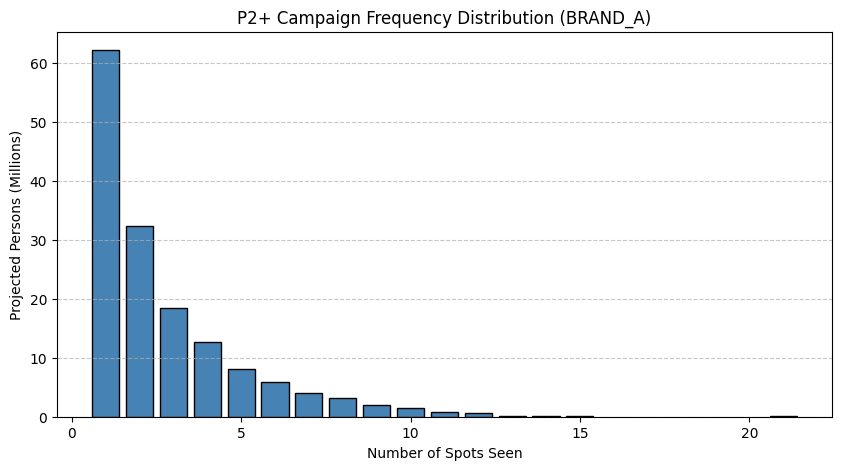

Share of impressions at 5+ exposures: 0.444


In [14]:
# Count how many spots each reached person saw and project using monthly weights
person_freq = exposures.groupby('respondent_id').agg(
    spots_seen=('ad_airing_id', 'nunique'),
    total_imp_weight=('weight', 'sum')
).reset_index()
person_freq['monthly_weight'] = person_freq['respondent_id'].map(monthly_weights)

freq_dist = person_freq.groupby('spots_seen')['monthly_weight'].sum() / 1e6

# plot: projected persons (M) by number of spots seen
plt.figure(figsize=(10, 5))
plt.bar(freq_dist.index, freq_dist.values, color='steelblue', edgecolor='black')
plt.xlabel("Number of Spots Seen")
plt.ylabel("Projected Persons (Millions)")
plt.title("P2+ Campaign Frequency Distribution (BRAND_A)")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

imp_5plus_share = person_freq[person_freq['spots_seen'] >= 5]['total_imp_weight'].sum() / person_freq['total_imp_weight'].sum()
print("Share of impressions at 5+ exposures:", round(imp_5plus_share, 3))

**Answer:** The average frequency is not a fair summary of the typical viewer's experience because the frequency distribution is heavily right-skewed. The vast majority of reached viewers only saw the commercial 1 or 2 times, while a small segment of heavy TV viewers saw it 5 or more times and absorbed a disproportionately large share of total impressions, pulling the average up.

## Task 2.3 — On target?

In [15]:
target_imp_share = ba_spots['a1849_imp'].sum() / ba_spots['p2_imp'].sum()
print("Share of impressions on A18-49:", round(target_imp_share, 3))

Share of impressions on A18-49: 0.194


**Answer:** Although A18-49 represents about 42% of the population, a much smaller share of the campaign's impressions landed on this target, meaning the media plan significantly under-delivered against the people it was bought for. This happens because many spots were placed on older-skewing networks like FNC, CBS, HGTV, and HIST, where the majority of viewers are 55+ rather than adults 18-49.

## Task 3.1 — Cost

In [16]:
campaign_cost = ba_spots['cost_usd'].sum()
p2_cpm = campaign_cost / (ba_spots['p2_imp'].sum() / 1000.0)
p2_cpp = campaign_cost / p2_grps
a1849_cpm = campaign_cost / (ba_spots['a1849_imp'].sum() / 1000.0)
a1849_cpp = campaign_cost / a1849_grps

print("Campaign cost (USD):", round(campaign_cost))
print("P2+ CPM (USD):", round(p2_cpm, 2))
print("P2+ CPP (USD):", round(p2_cpp))
print("A18-49 CPM (USD):", round(a1849_cpm, 2))
print("A18-49 CPP (USD):", round(a1849_cpp))

Campaign cost (USD): 7420270
P2+ CPM (USD): 17.72
P2+ CPP (USD): 56221
A18-49 CPM (USD): 91.53
A18-49 CPP (USD): 122836


## Task 3.2 — By network

In [17]:
# table: spots, cost, impressions, P2+ CPM and A18-49 CPM by network
net_table = ba_spots.groupby('network_code').agg(
    spots=('ad_airing_id', 'count'),
    cost_usd=('cost_usd', 'sum'),
    p2_imp=('p2_imp', 'sum'),
    a1849_imp=('a1849_imp', 'sum')
).reset_index()

net_table['cost_usd'] = net_table['cost_usd'].round(0).astype(int)
net_table['p2_impressions_M'] = (net_table['p2_imp'] / 1e6).round(1)
net_table['a1849_impressions_M'] = (net_table['a1849_imp'] / 1e6).round(1)
net_table['p2_cpm_usd'] = (net_table['cost_usd'] / (net_table['p2_imp'] / 1000.0)).round(2)
net_table['a1849_cpm_usd'] = (net_table['cost_usd'] / (net_table['a1849_imp'] / 1000.0)).round(2)

cols_order = ['network_code', 'spots', 'cost_usd', 'p2_impressions_M', 'a1849_impressions_M', 'p2_cpm_usd', 'a1849_cpm_usd']
net_table = net_table[cols_order].sort_values('cost_usd', ascending=False).reset_index(drop=True)
display(net_table)

,network_code,spots,cost_usd,p2_impressions_M,a1849_impressions_M,p2_cpm_usd,a1849_cpm_usd
0,FOX,13,2434700,76.3,18.4,31.93,132.03
1,ABC,29,1625700,94.2,17.0,17.26,95.69
2,CBS,22,1488700,89.0,13.7,16.73,108.72
3,NBC,16,796800,41.4,7.8,19.23,101.72
4,FNC,40,526300,57.8,2.7,9.11,193.70
5,HGTV,39,230000,24.7,7.6,9.33,30.45
6,FOOD,33,96620,9.5,3.0,10.19,32.29
7,FX,38,92200,8.5,5.6,10.82,16.61
8,HIST,37,79640,12.3,2.5,6.46,32.05
9,BRAVO,33,49610,5.1,2.8,9.76,17.61


**Answer:** Most of the campaign budget was spent on the big broadcast networks (CBS, NBC, ABC, FOX) because their rate-card prices (especially in prime time and sports) are much higher than cable. However, younger-skewing cable networks like FX and BRAVO (along with lower-cost cable inventory like FOOD) delivered the lowest A18-49 CPMs, making them the most cost-efficient way to reach the target audience.

## Task 3.3 — Guarantee

In [18]:
guarantee_met = bool(p2_grps >= 150.0)
make_good_grps = max(0.0, 150.0 - p2_grps)
make_good_value = make_good_grps * p2_cpp

print("Guarantee met:", guarantee_met)
print("Make-good GRPs owed:", round(make_good_grps, 1))
print("Value of make-goods (USD):", round(make_good_value))

Guarantee met: False
Make-good GRPs owed: 18.0
Value of make-goods (USD): 1012882


## Task 4 — Do networks add up?

In [19]:
big_nets = ['CBS', 'NBC', 'ABC', 'FOX', 'FNC']
small_nets = ['FX', 'BRAVO', 'HGTV', 'FOOD', 'HIST']

big_reached_ids = set(exposures[exposures['network_code'].isin(big_nets)]['respondent_id'])
small_reached_ids = set(exposures[exposures['network_code'].isin(small_nets)]['respondent_id'])
overlap_ids = big_reached_ids.intersection(small_reached_ids)

reach_big = (monthly_weights.reindex(list(big_reached_ids)).sum() / total_p2_reach_univ) * 100
reach_small = (monthly_weights.reindex(list(small_reached_ids)).sum() / total_p2_reach_univ) * 100
reach_whole = p2_reach

overlap_pct = (monthly_weights.reindex(list(overlap_ids)).sum() / total_p2_reach_univ) * 100
overlap_indep_pct = (reach_big * reach_small) / 100.0

reach_added_small = reach_whole - reach_big
cost_big = ba_spots[ba_spots['network_code'].isin(big_nets)]['cost_usd'].sum()
cost_small = ba_spots[ba_spots['network_code'].isin(small_nets)]['cost_usd'].sum()

cost_per_added_pt_small = cost_small / reach_added_small
cost_per_pt_big = cost_big / reach_big

print("Reach, big networks (%):", round(reach_big, 1))
print("Reach, small networks (%):", round(reach_small, 1))
print("Reach, whole campaign (%):", round(reach_whole, 1))
print("Overlap (%):", round(overlap_pct, 1))
print("Overlap if independent (%):", round(overlap_indep_pct, 1))
print("Reach added by small networks (points):", round(reach_added_small, 1))
print("Cost per added reach point, small (USD):", round(cost_per_added_pt_small))
print("Cost per reach point, big (USD):", round(cost_per_pt_big))

Reach, big networks (%): 39.8
Reach, small networks (%): 12.4
Reach, whole campaign (%): 43.5
Overlap (%): 8.7
Overlap if independent (%): 4.9
Reach added by small networks (points): 3.7
Cost per added reach point, small (USD): 148706
Cost per reach point, big (USD): 172456


**Answer:** Reach does not add up across networks because many viewers watch both big and small networks, creating audience duplication (overlap). The actual overlap is higher than what we would expect under independence, meaning viewers of small cable networks are more likely than average to also be reached by big networks because they are heavier TV viewers overall. Still, because cable spots are much cheaper, the cost per incremental reach point added by the small networks is quite reasonable compared to the average cost per reach point on the expensive big networks.

## Task 5 — How sure are we?

In [20]:
# Unweighted panelists (R and L) per spot
panelist_counts = exposures.groupby('ad_airing_id')['respondent_id'].nunique()
ba_spots['panelists'] = ba_spots['ad_airing_id'].map(panelist_counts).fillna(0).astype(int)

# Number of persons in-tab each broadcast day
daily_n_intab = dw_persons.groupby('broadcast_date')['respondent_id'].nunique()
ba_spots['n_intab'] = ba_spots['broadcast_date'].map(daily_n_intab)

# Standard error (in rating points) and relative SE (SE / rating)
p_frac = ba_spots['p2_rating'] / 100.0
ba_spots['se_rating'] = np.sqrt(p_frac * (1.0 - p_frac) / ba_spots['n_intab']) * 100.0
ba_spots['rel_se'] = np.where(ba_spots['p2_rating'] > 0, ba_spots['se_rating'] / ba_spots['p2_rating'], np.nan)

# table: median panelists per spot and median relative SE, by network
se_table = ba_spots.groupby('network_code').agg(
    median_panelists=('panelists', 'median'),
    median_rel_se=('rel_se', 'median')
).reset_index()
se_table['median_panelists'] = se_table['median_panelists'].round(1)
se_table['median_rel_se'] = se_table['median_rel_se'].round(3)
se_table = se_table.sort_values('median_panelists', ascending=False).reset_index(drop=True)
display(se_table)

zero_panelist_spots = int((ba_spots['panelists'] == 0).sum())
med_rel_se_big = ba_spots[ba_spots['network_code'].isin(big_nets)]['rel_se'].median()
med_rel_se_small = ba_spots[ba_spots['network_code'].isin(small_nets)]['rel_se'].median()

# W18-34 zero-cell spots
w1834_spot_counts = exposures[exposures['respondent_id'].isin(w18_34_set)].groupby('ad_airing_id')['respondent_id'].nunique()
ba_spots['w1834_panelists'] = ba_spots['ad_airing_id'].map(w1834_spot_counts).fillna(0).astype(int)
w1834_zero_spots = int((ba_spots['w1834_panelists'] == 0).sum())

print("Spots seen by no panelist:", zero_panelist_spots)
print("Median relative SE, big networks:", round(med_rel_se_big, 3))
print("Median relative SE, small networks:", round(med_rel_se_small, 3))
print("W18-34 zero-cell spots:", w1834_zero_spots)

,network_code,median_panelists,median_rel_se
0,FOX,145.0,0.080
1,CBS,69.0,0.113
2,NBC,68.5,0.115
3,ABC,57.0,0.123
4,FNC,31.0,0.164
5,HGTV,11.0,0.301
6,FX,5.5,0.423
7,FOOD,5.0,0.423
8,HIST,5.0,0.460
9,BRAVO,3.0,0.540


Spots seen by no panelist: 10
Median relative SE, big networks: 0.122
Median relative SE, small networks: 0.417
W18-34 zero-cell spots: 171


**Answer:** A spot seen by no panelist gets a rating of 0.0, which does not mean literally zero people in the US watched it—it just means the audience at that moment was too small for a panel of ~9,268 in-tab people to capture even a single viewer. This shows that on small cable networks (where the median spot is seen by only 3 to 11 panelists and relative SE is around 41.7%), single-spot ratings are extremely noisy and near the detection limit of the panel. If the client asked for spot-by-spot W18-34 ratings (where 171 of the 300 spots are zero-cells), I would tell them that single-spot estimates for such a narrow demographic are statistically unreliable due to massive sampling error, so we must evaluate W18-34 performance at the aggregated campaign or daypart level instead.

## Bonus

**Answer:** To lower the target A18-49 CPM and increase A18-49 impressions, I propose moving the budget of 20 spots from older-skewing, high-CPM broadcast and news dayparts (such as FNC and CBS Daytime/Early Morning, where A18-49 CPMs are among the highest in the plan) into FX and BRAVO prime/evening rotators. Based on our campaign table in Task 3.2, FX and BRAVO deliver the lowest A18-49 CPMs in the entire plan (and FX has the highest share of young adult viewers at 26.6% from Lab 1). Reallocating those 20 spots to FX and BRAVO at their much lower rate-card prices buys significantly more target A18-49 impressions for the exact same budget, directly cutting the overall campaign A18-49 CPM.
